<a href="https://colab.research.google.com/github/moyan-li/MSSP607/blob/main/WeeklyModules/Week08/week8_participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from google.colab import userdata
import os

github_token = userdata.get('Key1')
owner = 'moyan-li' # Replace with the GitHub repository owner
repository = 'MSSP607' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
!git clone {clone_url}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'MSSP607'...
remote: Enumerating objects: 312, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 312 (delta 48), reused 20 (delta 15), pack-reused 221 (from 1)
Receiving objects: 100% (312/312), 12.66 MiB | 17.02 MiB/s, done.
Resolving deltas: 100% (157/157), done.


Rows used: 60,398; rows excluded: 0
Date range: 2010-12-29 to 2014-01-28

Historical yearly sales:
             Sales  FirstDate   LastDate  MonthsCovered
Year                                                   
2010     43,421.04 2010-12-29 2010-12-31              1
2011  7,075,525.93 2011-01-01 2011-12-31             12
2012  5,842,485.20 2012-01-01 2012-12-31             12
2013 16,351,550.34 2013-01-01 2013-12-31             12
2014     45,694.72 2014-01-01 2014-01-28              1

Five-year sales forecast:
 Year  ForecastSales
 2015  23,670,557.10
 2016  28,308,569.31
 2017  32,946,581.52
 2018  37,584,593.72
 2019  42,222,605.93

Top 10 products by historical sales amount:
                          TotalSales  OrderLines  UnitsSold  AverageSalePerLine
EnglishProductName                                                             
Mountain-200 Black, 46  1,373,469.55         620        620            2,215.27
Mountain-200 Black, 42  1,363,142.09         614        614            

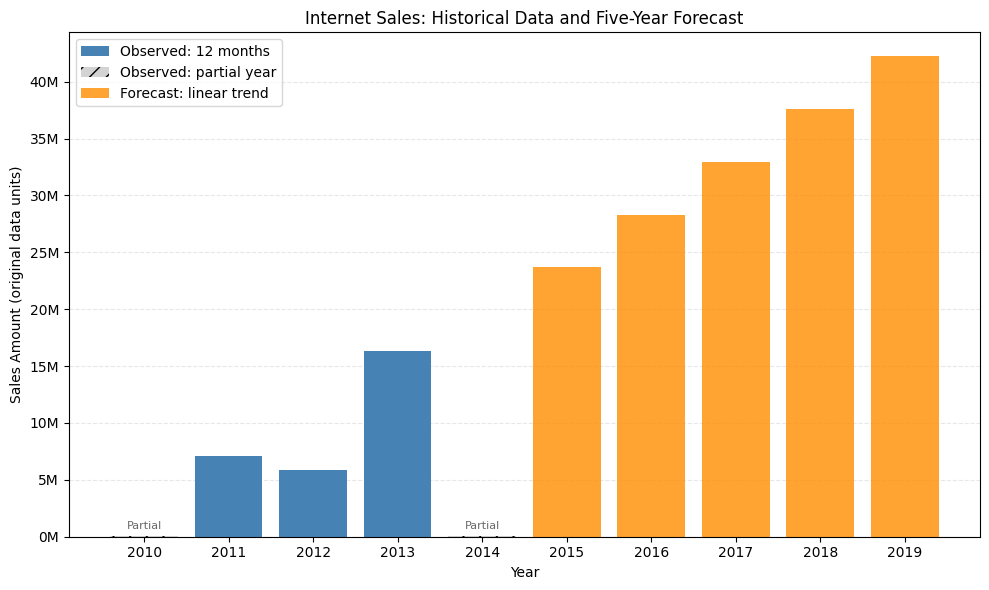


Caution: The forecast extrapolates only three years of training data.
Having activity in all 12 months does not by itself prove that a year is complete.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Upload InternetSales.csv to the Files panel in Colab before running.
file = "/content/MSSP607/WeeklyModules/Week08/InternetSales.csv"

# This dataset uses Windows-1252 encoding rather than UTF-8.
sales = pd.read_csv(
    file,
    encoding="cp1252",
    usecols=["OrderDate", "SalesAmount", "EnglishProductName", "OrderQuantity"],
)

sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], errors="coerce")
sales["SalesAmount"] = pd.to_numeric(sales["SalesAmount"], errors="coerce")
sales["OrderQuantity"] = pd.to_numeric(sales["OrderQuantity"], errors="coerce")
before_cleaning = len(sales)
sales = sales.dropna(subset=["OrderDate", "SalesAmount", "EnglishProductName"])
sales["Year"] = sales["OrderDate"].dt.year
print(f"Rows used: {len(sales):,}; rows excluded: {before_cleaning - len(sales):,}")
print(f"Date range: {sales['OrderDate'].min().date()} to {sales['OrderDate'].max().date()}")

# Annual totals. Years with activity in fewer than 12 months are displayed,
# but are excluded from training so partial years are not treated as full years.
annual = sales.groupby("Year").agg(
    Sales=("SalesAmount", "sum"),
    FirstDate=("OrderDate", "min"),
    LastDate=("OrderDate", "max"),
    MonthsCovered=("OrderDate", lambda x: x.dt.month.nunique()),
)
print("\nHistorical yearly sales:")
print(annual.to_string(float_format=lambda value: f"{value:,.2f}"))

training = annual[annual["MonthsCovered"] == 12]
if len(training) < 2:
    raise ValueError("At least two years with sales in all 12 months are needed.")

# Fit a simple linear trend to yearly sales and forecast the five calendar
# years after the last year with observations in the data.
first_training_year = int(training.index.min())
x = training.index.to_numpy() - first_training_year
slope, intercept = np.polyfit(x, training["Sales"].to_numpy(), 1)
last_observed_year = int(annual.index.max())
future_years = np.arange(last_observed_year + 1, last_observed_year + 6)
forecast_values = slope * (future_years - first_training_year) + intercept
forecast = pd.DataFrame({"Year": future_years, "ForecastSales": forecast_values})
print("\nFive-year sales forecast:")
print(forecast.to_string(index=False, float_format=lambda value: f"{value:,.2f}"))

# Compare the sum of SalesAmount for each exact product name. The result is
# a historical ranking, not proof of which product will lead in the future.
product_summary = (
    sales.groupby("EnglishProductName")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        OrderLines=("SalesAmount", "size"),
        UnitsSold=("OrderQuantity", "sum"),
        AverageSalePerLine=("SalesAmount", "mean"),
    )
    .sort_values("TotalSales", ascending=False)
)
print("\nTop 10 products by historical sales amount:")
print(product_summary.head(10).to_string(float_format=lambda value: f"{value:,.2f}"))
top_product = product_summary.index[0]
print(f"\nHistorical sales leader: {top_product}")
print("It is a candidate for future sales leadership if historical patterns persist, not a guaranteed forecast.")

# Visualize historical full and partial years separately from forecast years.
fig, ax = plt.subplots(figsize=(10, 6))
partial = annual[annual["MonthsCovered"] < 12]
ax.bar(training.index, training["Sales"], label="Observed: 12 months", color="steelblue")
ax.bar(partial.index, partial["Sales"], label="Observed: partial year", color="lightgray", hatch="//")
ax.bar(future_years, forecast_values, label="Forecast: linear trend", color="darkorange", alpha=0.8)
for year, row in partial.iterrows():
    ax.annotate("Partial", (year, row["Sales"]), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=8, color="dimgray")
ax.set_title("Internet Sales: Historical Data and Five-Year Forecast")
ax.set_xlabel("Year")
ax.set_ylabel("Sales Amount (original data units)")
ax.set_xticks(np.arange(int(annual.index.min()), int(future_years.max()) + 1))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value / 1_000_000:,.0f}M"))
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()

print("\nCaution: The forecast extrapolates only three years of training data.")
print("Having activity in all 12 months does not by itself prove that a year is complete.")
